In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/segmentation.csv') # вот здесь свой путь укажите

# Обучаем K-Means на 4 кластера
kmeans = KMeans(n_clusters=4, random_state=42)
df['cluster'] = kmeans.fit_predict(df[['recency', 'frequency', 'monetary']])

# Смотрим средние значения по кластерам, чтобы понять, кто есть кто
cluster_summary = df.groupby('cluster')[['recency', 'frequency', 'monetary']].mean().round(1)
print(cluster_summary)

         recency  frequency  monetary
cluster                              
0           46.5        1.1      50.5
1           53.5        2.3     486.4
2           50.9        1.5     181.4
3           43.5        3.0    1193.2


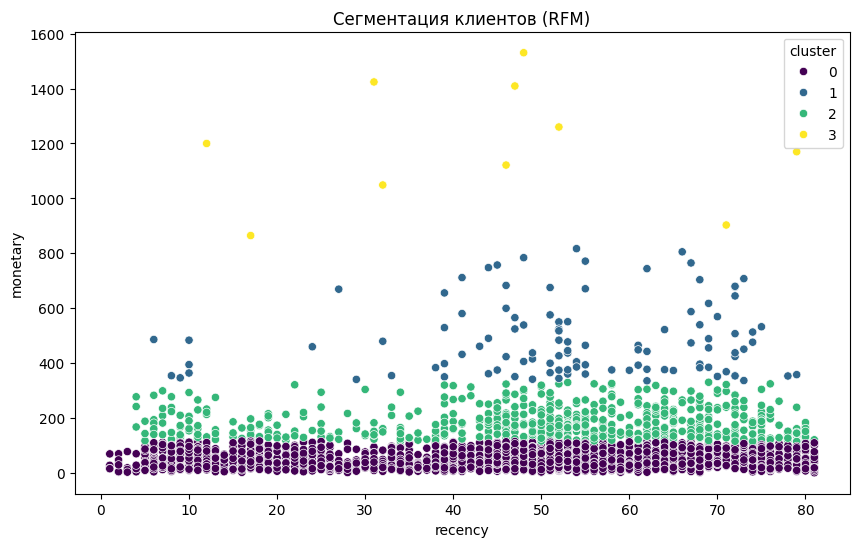

In [5]:
# Визуализация
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='recency', y='monetary', hue='cluster', palette='viridis')
plt.title('Сегментация клиентов (RFM)')
plt.show()

**Кластер 3 Желтый - «VIP / Лояльные»**

Цифры: Самая высокая сумма покупок monetary = 1193, самая высокая частота frequency = 3.0 и самая низкая давность recency = 43.5, т.е. покупали недавно.

Бизнес-действие: Их надо беречь. Давать ранний доступ к новинкам, персональные скидки, не спамить, а предлагать премиум-услуги.

**Кластер 1 Синий - «Уходящие / В зоне риска»**

Цифры: Хорошая сумма monetary = 486, средняя частота 2.3, но самая высокая давность recency = 53.5, т.е. давно не покупали.

Бизнес-действие: Это бывшие активные клиенты, которые остыли. Для них нужно запустить кампанию рассылка с промокодом по типу "Мы скучали, возвращайтесь".

**Кластер 2 Зеленый - «Средний чек»**

Цифры: Средняя сумма monetary = 181, низкая частота 1.5.

Бизнес-действие: Стимулировать к повторным покупкам, предлагать бесплатную доставку от определенной суммы, чтобы повысить чек.

**Кластер 0 Фиолетовый - «Новички / Одноразовые»**

Цифры: Самая низкая сумма monetary = 50 и частота 1.1.

Бизнес-действие: Сделать так, чтобы они купили во второй раз.